# Neuron playground: learning rate, steps and adding neurons

This notebook builds on `single_neuron.py` and `two_neurons.py`. It answers three questions by running experiments:

1. **Learning rate (`alpha`)**: how big should each gradient step be?
2. **Number of steps (`nsteps`)**: how long should we train?
3. **Adding neurons**: what can a network with more neurons learn that one neuron cannot?

Each experiment changes one setting and keeps everything else fixed, so any difference in the plots comes from that setting.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi':100,'axes.spines.top':False,'axes.spines.right':False})

## Part 1: one neuron, one example

These are the same pieces as `single_neuron.py`: weighted sum → sigmoid → sigmoid loss → gradient → update.
The only change is that the training loop now sits inside a function, so we can call it with many different settings.

In [2]:
def weighted_sum(x_inp,weights,bias):
    return weights@x_inp+bias          # s = w1*x1 + w2*x2 + ... + b

def sigmoid(s):
    return 1/(1+np.exp(-s))            # squashes s to between 0 and 1

def sigmoid_loss(s,target):
    m=2*target-1                       # target 0 or 1 becomes -1 or +1
    return sigmoid(-m*s)               # L = sigmoid(-m*s)

def sigmoid_loss_gradient(s,target):
    m=2*target-1
    loss=sigmoid_loss(s,target)
    return -m*loss*(1-loss)            # dL/ds = -m * L * (1-L)


x_inp=np.array([1,2,3,4])
start_weights=np.array([0.11,0.12,0.13,0.14])
target=0

def train_neuron(alpha,nsteps,weights=start_weights,bias=0):
    # returns the loss after 0, 1, ..., nsteps updates
    losses=[]
    for step in range(nsteps+1):
        s=weighted_sum(x_inp,weights,bias)
        losses.append(sigmoid_loss(s,target))
        if step==nsteps:
            break
        dL_ds=sigmoid_loss_gradient(s,target)
        weights=weights-alpha*dL_ds*x_inp  # ds/dw = x
        bias=bias-alpha*dL_ds              # ds/db = 1
    return np.array(losses)

losses=train_neuron(alpha=0.05,nsteps=100)
print(f"loss before: {losses[0]:.3f}   after 100 steps: {losses[-1]:.3f}")

loss before: 0.786   after 100 steps: 0.007


### 1a. Changing the learning rate

The update is `weights = weights - alpha * gradient`. `alpha` sets the step size:

* too small → every step is tiny and the loss barely moves
* larger → the loss drops in far fewer steps

Every curve below starts from the same weights and runs for the same 100 steps.

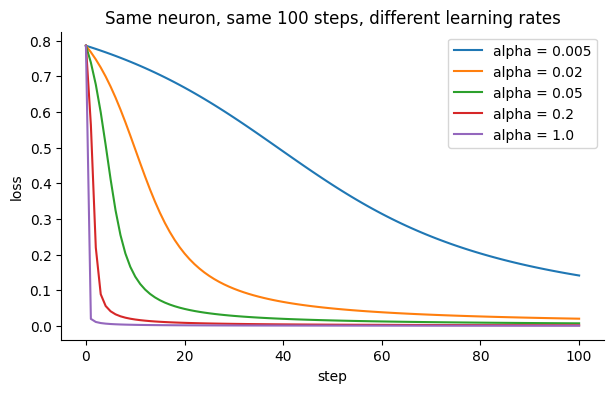

In [3]:
alphas=[0.005,0.02,0.05,0.2,1.0]
nsteps=100

fig,ax=plt.subplots(figsize=(7,4))
for alpha in alphas:
    ax.plot(train_neuron(alpha,nsteps),label=f'alpha = {alpha}')
ax.set(xlabel='step',ylabel='loss',title=f'Same neuron, same {nsteps} steps, different learning rates')
ax.legend()
plt.show()

Note that the curves flatten out as they get close to zero. The gradient `-m * L * (1-L)` shrinks with the loss, so steps get smaller near the end even when `alpha` stays the same.

### 1b. Changing the number of steps

More steps give the neuron more chances to improve. A small `alpha` needs many more steps to reach the same loss as a large one: roughly, what matters is **alpha × nsteps**, the total distance the weights are allowed to travel.

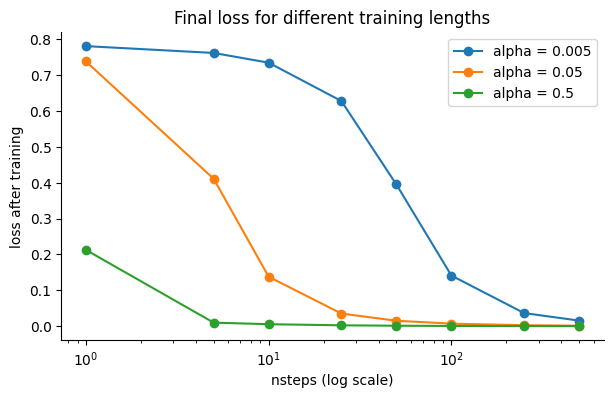

In [4]:
step_counts=[1,5,10,25,50,100,250,500]

fig,ax=plt.subplots(figsize=(7,4))
for alpha in [0.005,0.05,0.5]:
    final=[train_neuron(alpha,n)[-1] for n in step_counts]
    ax.plot(step_counts,final,'o-',label=f'alpha = {alpha}')
ax.set(xscale='log',xlabel='nsteps (log scale)',ylabel='loss after training',
       title='Final loss for different training lengths')
ax.legend()
plt.show()

### 1c. Both at once

Each square is one full training run. Dark means a low final loss. The bright corner (small `alpha`, few steps) has not trained enough; the dark corner has. Squares with the same `alpha × nsteps` end up with similar colors, which is why the dark region follows a diagonal.

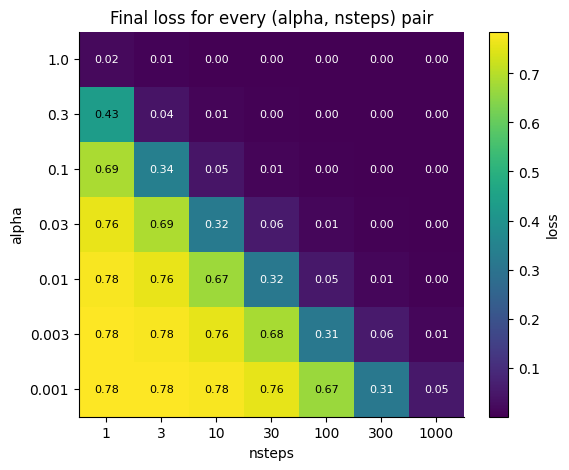

In [5]:
grid_alphas=[0.001,0.003,0.01,0.03,0.1,0.3,1.0]
grid_steps=[1,3,10,30,100,300,1000]
final_loss=np.array([[train_neuron(a,n)[-1] for n in grid_steps] for a in grid_alphas])

fig,ax=plt.subplots(figsize=(6.5,5))
im=ax.imshow(final_loss,cmap='viridis',origin='lower')
ax.set(xticks=range(len(grid_steps)),xticklabels=grid_steps,
       yticks=range(len(grid_alphas)),yticklabels=grid_alphas,
       xlabel='nsteps',ylabel='alpha',title='Final loss for every (alpha, nsteps) pair')
for i in range(len(grid_alphas)):
    for j in range(len(grid_steps)):
        v=final_loss[i,j]
        ax.text(j,i,f'{v:.2f}',ha='center',va='center',fontsize=8,color='white' if v<0.4 else 'black')
fig.colorbar(im,label='loss')
plt.show()

## Part 2: adding neurons

One example is too easy: a single neuron can always fit it. To see why we would want more neurons we need a harder problem.

**The task:** points in a square. A point is class 1 (blue) if it lies inside a circle and class 0 (orange) if it lies outside.

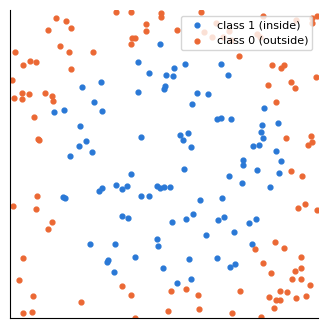

47% of the points are class 1


In [6]:
rng=np.random.default_rng(0)
X=rng.uniform(-1,1,size=(200,2))              # 200 points, 2 inputs each
y=(np.sum(X**2,axis=1)<0.637).astype(int)     # radius chosen so about half are inside

BLUE,ORANGE='#2a78d6','#eb6834'

def plot_points(ax):
    ax.scatter(*X[y==1].T,s=12,color=BLUE,label='class 1 (inside)')
    ax.scatter(*X[y==0].T,s=12,color=ORANGE,label='class 0 (outside)')
    ax.set(aspect='equal',xlim=(-1,1),ylim=(-1,1),xticks=[],yticks=[])

fig,ax=plt.subplots(figsize=(4,4))
plot_points(ax)
ax.legend(loc='upper right',fontsize=8)
plt.show()
print(f"{y.mean():.0%} of the points are class 1")

### A network with a hidden layer

`two_neurons.py` already wired up the shape we need: inputs → **hidden neurons** → one output neuron. Each hidden neuron is an ordinary sigmoid neuron. The output neuron treats the hidden outputs as its inputs.

```
x1 ──┬──► hidden 1 ──┐
     ├──► hidden 2 ──┼──► output
x2 ──┴──► hidden 3 ──┘
```

Training works exactly like before, with one new step. The chain rule passes the gradient backwards *through* the output neuron to reach the hidden weights. This is **backpropagation**.

With `hidden=0` there is no hidden layer and the network is just the single neuron from Part 1.

**A change of loss.** The sigmoid loss `sigmoid(-m*s)` has a weakness: when a point is *confidently wrong*, its loss is close to 1 and flat, so its gradient is close to 0 and the network stops trying to fix it. On this dataset that makes every network quickly settle on "everything is class 0". The cell after the next one shows this. From here on we use the **cross-entropy** loss:

$$L = -\big[\,t\log p + (1-t)\log(1-p)\,\big], \qquad p=\sigma(s)$$

Its gradient is simply $\;dL/ds = p - t$, which stays large for confidently wrong points.

In [7]:
def init_network(n_inputs,hidden,seed=0):
    r=np.random.default_rng(seed)  # seed fixes the random starting weights
    sizes=[n_inputs,hidden,1] if hidden>0 else [n_inputs,1]
    return [dict(W=r.normal(0,0.5,size=(n_out,n_in)),b=np.zeros(n_out))
            for n_in,n_out in zip(sizes[:-1],sizes[1:])]

def forward(layers,X):
    # returns the activations of every layer; the last one is s (before the final sigmoid)
    acts=[X]
    for k,layer in enumerate(layers):
        s=acts[-1]@layer['W'].T+layer['b']
        last=(k==len(layers)-1)
        acts.append(s[:,0] if last else sigmoid(s))
    return acts

def cross_entropy(s,y):
    p=np.clip(sigmoid(s),1e-12,1-1e-12)
    return -np.mean(y*np.log(p)+(1-y)*np.log(1-p))

def mean_sigmoid_loss(s,y):
    return np.mean(sigmoid_loss(s,y))

def train_network(hidden,alpha,nsteps,loss='cross_entropy',seed=0,snapshots=()):
    layers=init_network(X.shape[1],hidden,seed)
    losses,saved=[],{}
    for step in range(nsteps+1):
        if step in snapshots:
            saved[step]=[dict(W=l['W'].copy(),b=l['b'].copy()) for l in layers]

        # forward
        acts=forward(layers,X)
        s=acts[-1]
        if loss=='cross_entropy':
            losses.append(cross_entropy(s,y))
            dL_ds=(sigmoid(s)-y)/len(y)                  # dL/ds = p - t, averaged over the points
        else:
            losses.append(mean_sigmoid_loss(s,y))
            dL_ds=sigmoid_loss_gradient(s,y)/len(y)
        if step==nsteps:
            break

        # backward: walk from the output layer to the first layer
        delta=dL_ds[:,None]                              # dL/ds for this layer, one row per point
        for k in reversed(range(len(layers))):
            a_in=acts[k]                                 # inputs to layer k
            dW=delta.T@a_in                              # because ds/dW = input
            db=delta.sum(axis=0)                         # because ds/db = 1
            if k>0:
                # pass the gradient back through this layer's weights and the hidden sigmoid
                delta=(delta@layers[k]['W'])*a_in*(1-a_in)   # sigmoid'(s) = σ(s)(1-σ(s))
            layers[k]['W']=layers[k]['W']-alpha*dW
            layers[k]['b']=layers[k]['b']-alpha*db
    return layers,np.array(losses),saved

def accuracy(layers):
    return np.mean((forward(layers,X)[-1]>0)==y)        # s>0 means output>0.5, i.e. predicts class 1

First, the problem with the sigmoid loss. Even with 8 hidden neurons it ends up labelling almost every point as class 0, which is right only about half the time. Cross-entropy on the identical network does far better.

In [8]:
for name in ['sigmoid_loss','cross_entropy']:
    layers,_,_=train_network(hidden=8,alpha=1.0,nsteps=3000,loss=name)
    predicted=np.mean(forward(layers,X)[-1]>0)
    print(f"{name:14s} accuracy: {accuracy(layers):.0%}   points predicted as class 1: {predicted:.0%}")

sigmoid_loss   accuracy: 53%   points predicted as class 1: 0%


cross_entropy  accuracy: 98%   points predicted as class 1: 46%


### What each extra neuron buys

A single neuron outputs 0.5 along a **straight line** (where `s = w1*x1 + w2*x2 + b = 0`), so its boundary between class 0 and class 1 is always a line. No line can separate the inside of a circle from the outside.

Each hidden neuron contributes one line, and the output neuron combines them. Three lines can enclose a triangle. More neurons give more lines, so the boundary can get closer to a circle.

The shading shows the network's output across the square, and the black curve is where it equals 0.5.

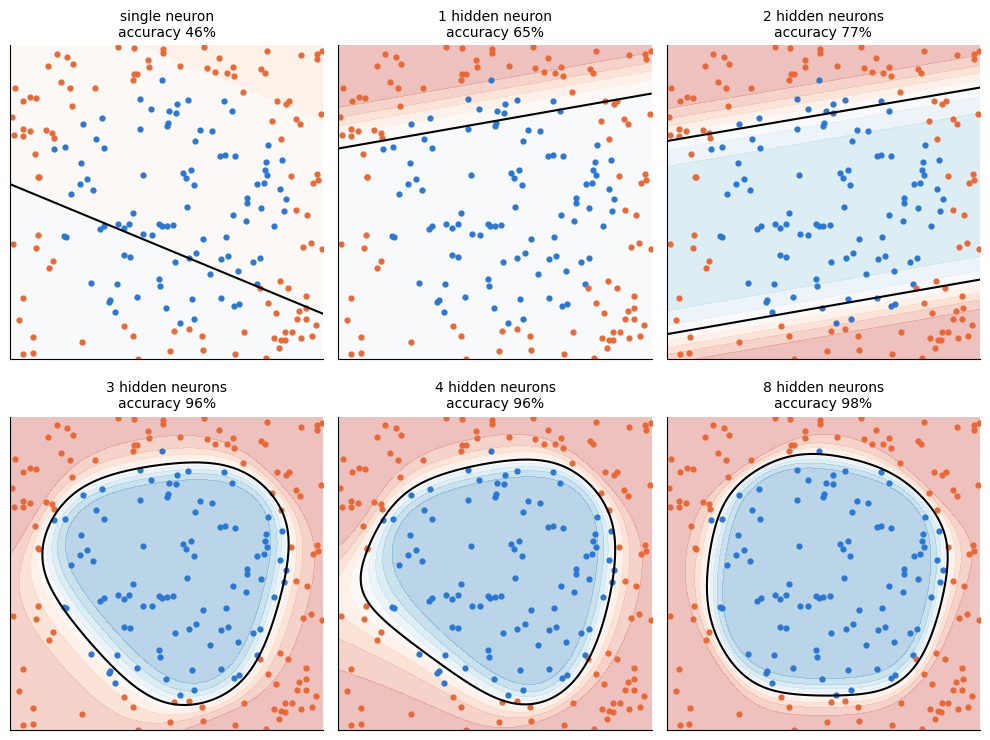

In [9]:
grid=np.linspace(-1,1,200)
gx,gy=np.meshgrid(grid,grid)
grid_points=np.column_stack([gx.ravel(),gy.ravel()])

def plot_boundary(ax,layers,title):
    out=sigmoid(forward(layers,grid_points)[-1]).reshape(gx.shape)
    ax.contourf(gx,gy,out,levels=np.linspace(0,1,11),cmap='RdBu',alpha=0.35,vmin=-0.2,vmax=1.2)
    ax.contour(gx,gy,out,levels=[0.5],colors='black',linewidths=1.5)
    plot_points(ax)
    ax.set_title(title,fontsize=10)

hidden_sizes=[0,1,2,3,4,8]
alpha,nsteps=1.0,3000
runs={h:train_network(h,alpha,nsteps) for h in hidden_sizes}

fig,axes=plt.subplots(2,3,figsize=(10,7.8))
for ax,h in zip(axes.flat,hidden_sizes):
    layers,_,_=runs[h]
    label='single neuron' if h==0 else f'{h} hidden neuron'+'s'*(h>1)
    plot_boundary(ax,layers,f'{label}\naccuracy {accuracy(layers):.0%}')
plt.tight_layout()
plt.show()

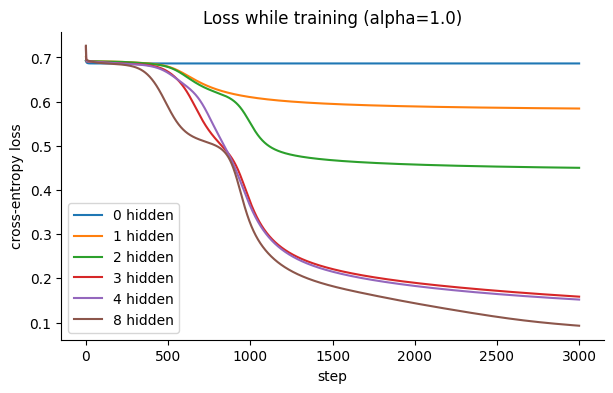

In [10]:
fig,ax=plt.subplots(figsize=(7,4))
for h in hidden_sizes:
    ax.plot(runs[h][1],label=f'{h} hidden')
ax.set(xlabel='step',ylabel='cross-entropy loss',title=f'Loss while training (alpha={alpha})')
ax.legend()
plt.show()

### Learning rate with a hidden layer

The same trade-off as Part 1 shows up again with 8 hidden neurons. A tiny `alpha` barely moves in 3000 steps. A larger one learns fast. With very large values the curve becomes jumpy, because each step overshoots and undoes part of the previous one.

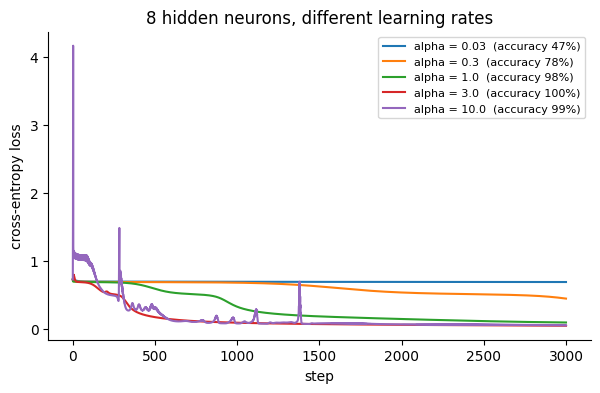

In [11]:
fig,ax=plt.subplots(figsize=(7,4))
for alpha in [0.03,0.3,1.0,3.0,10.0]:
    layers,losses,_=train_network(hidden=8,alpha=alpha,nsteps=3000)
    ax.plot(losses,label=f'alpha = {alpha}  (accuracy {accuracy(layers):.0%})')
ax.set(xlabel='step',ylabel='cross-entropy loss',title='8 hidden neurons, different learning rates')
ax.legend(fontsize=8)
plt.show()

### Watching the boundary form as steps increase

This is a single training run, photographed at different step counts. Stopping at `nsteps=100` gives the first picture, stopping at `nsteps=5000` gives the last.

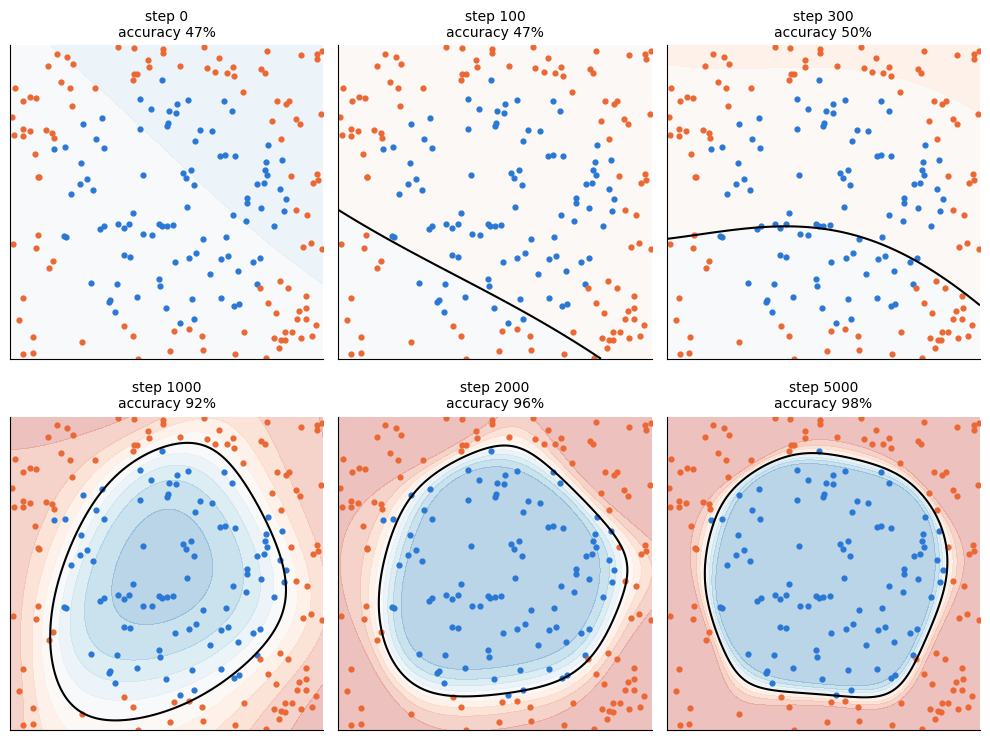

In [12]:
snapshot_steps=[0,100,300,1000,2000,5000]
_,_,saved=train_network(hidden=8,alpha=1.0,nsteps=max(snapshot_steps),snapshots=snapshot_steps)

fig,axes=plt.subplots(2,3,figsize=(10,7.8))
for ax,step in zip(axes.flat,snapshot_steps):
    plot_boundary(ax,saved[step],f'step {step}\naccuracy {accuracy(saved[step]):.0%}')
plt.tight_layout()
plt.show()

## Part 3: try it yourself

Move the sliders to retrain the network. (Needs `ipywidgets`. Without it, change the numbers in the call at the bottom of the cell.)

Things to try:

* `hidden=2`, then `3`: when does a closed shape first appear?
* `hidden=8` with `alpha=0.03`, then increase `nsteps`: can more steps make up for a small learning rate?
* Change `seed`: the starting weights are random, and some starts train better than others.

In [13]:
def explore(hidden=3,alpha=1.0,nsteps=2000,seed=0):
    layers,losses,_=train_network(hidden,alpha,nsteps,seed=seed)
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,4))
    plot_boundary(ax1,layers,f'hidden={hidden}, alpha={alpha}, nsteps={nsteps}\naccuracy {accuracy(layers):.0%}')
    ax2.plot(losses)
    ax2.set(xlabel='step',ylabel='cross-entropy loss',ylim=(0,None),title='loss')
    plt.show()

try:
    from ipywidgets import interact_manual,IntSlider,FloatLogSlider
    interact_manual(explore,
             hidden=IntSlider(value=3,min=0,max=16),
             alpha=FloatLogSlider(value=1.0,base=10,min=-2,max=1,step=0.25),
             nsteps=IntSlider(value=2000,min=0,max=8000,step=250),
             seed=IntSlider(value=0,min=0,max=9))
except ImportError:
    explore(hidden=3,alpha=1.0,nsteps=2000,seed=0)

interactive(children=(IntSlider(value=3, description='hidden', max=16), FloatLogSlider(value=1.0, description=…

## Summary

| setting | too small | too large |
|---|---|---|
| `alpha` | loss barely moves | steps overshoot and the loss jumps around |
| `nsteps` | training stops before the loss is low | wasted time once the loss has levelled off |
| hidden neurons | the boundary is too simple for the data (one neuron can only draw a line) | more weights to train and more time per step |

`alpha` and `nsteps` work together: a smaller learning rate needs more steps.